In [ ]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [2]:
# CARGAR MODELOS

reg_log_hta_class_weight = joblib.load("../models/reg_log_hta_class_weight.joblib")
reg_log_hta = joblib.load("../models/reg_log_hta.joblib")
reg_log_hta_smote = joblib.load("../models/reg_log_hta_smote.joblib")

In [5]:
# CARGAR LOS DATOS DE TEST 
X_test_hta = pd.read_csv("../data/processed/X_test_hta_df.csv")
y_test_hta = pd.read_csv("../data/processed/y_test_hta.csv")

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9072    0.7309    0.8096      2984
           1     0.5372    0.8069    0.6450      1155

    accuracy                         0.7521      4139
   macro avg     0.7222    0.7689    0.7273      4139
weighted avg     0.8040    0.7521    0.7636      4139

ROC-AUC Score: 0.8321


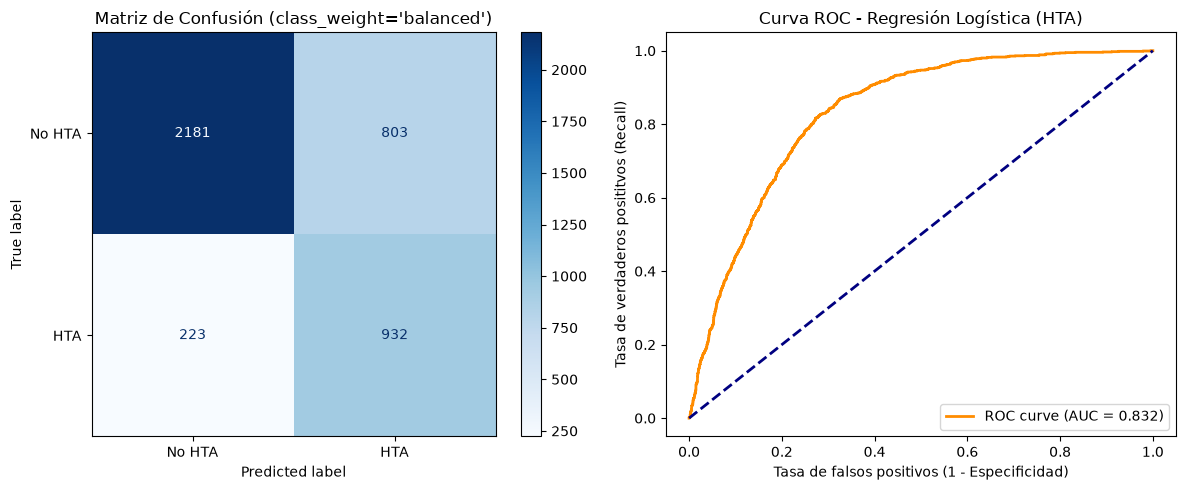

In [6]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_hta = reg_log_hta_class_weight.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos posititvos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9262    0.6689    0.7768      2984
           1     0.5020    0.8623    0.6346      1155

    accuracy                         0.7229      4139
   macro avg     0.7141    0.7656    0.7057      4139
weighted avg     0.8078    0.7229    0.7371      4139

ROC-AUC Score: 0.8283


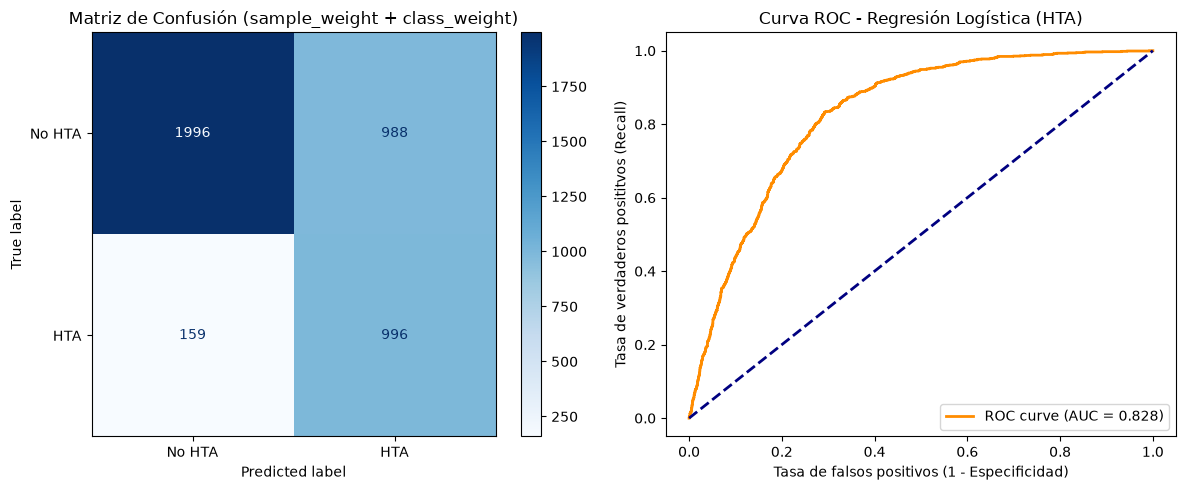

In [7]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_hta = reg_log_hta.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (sample_weight + class_weight)")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos posititvos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


In [9]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_hta >= u).astype(int)
    report = classification_report(
        y_test_hta, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]

    print(
        f"Umbral {u:.2f} -> Recall HTA: {rec*100:.2f}% | Precisión HTA: {prec*100:.2f}% | F1: {f1:.4f}"
    )

Umbral 0.35 -> Recall HTA: 93.25% | Precisión HTA: 43.98% | F1: 0.5977
Umbral 0.40 -> Recall HTA: 91.60% | Precisión HTA: 46.04% | F1: 0.6128
Umbral 0.45 -> Recall HTA: 88.92% | Precisión HTA: 47.95% | F1: 0.6230
Umbral 0.50 -> Recall HTA: 86.23% | Precisión HTA: 50.20% | F1: 0.6346
Umbral 0.55 -> Recall HTA: 82.94% | Precisión HTA: 52.41% | F1: 0.6423


HIPERTENSIÓN CON SMOTE
              precision    recall  f1-score   support

           0     0.9025    0.7383    0.8122      2984
           1     0.5400    0.7939    0.6428      1155

    accuracy                         0.7538      4139
   macro avg     0.7213    0.7661    0.7275      4139
weighted avg     0.8014    0.7538    0.7649      4139

ROC-AUC Score: 0.8308


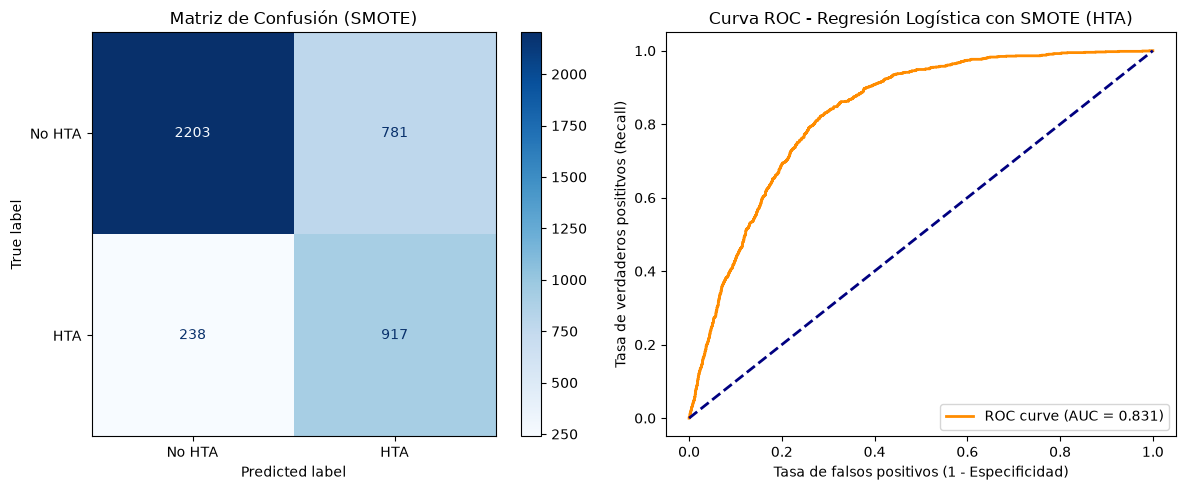

In [8]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_smote = reg_log_hta_smote.predict(X_test_hta)
y_proba_smote = reg_log_hta_smote.predict_proba(X_test_hta)[:, 1]

print("HIPERTENSIÓN CON SMOTE")
print(classification_report(y_test_hta, y_pred_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_hta, y_proba_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (SMOTE)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_hta, y_proba_smote)
auc_smote = roc_auc_score(y_test_hta, y_proba_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos posititvos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística con SMOTE (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### CONCLUSIONES METODOLÓGICAS 

- El modelo seleccionado como Baseline es la combinación de class_weight='balanced' + sample_weight (FACTORADULTO), el cual es la opción más robusta clínicamente. Este modelo logra reducir los Falsos Negativos a solo 159 casos, mientras que el modelo que solo usa class_weight este número aumenta a 223 y 238 para el modelo con SMOTE. 

- SMOTE vs. FACTORADULTO: SMOTE incrementa ligeramente la Esepcificidad y la precision, pero al no incluir el factor de elevación de la encuesta nacional, se pierde la capacidad de detección de enfermos (Recall cae a 79,39%)

- Por ultimo, el análisis de umbrales demuestra que la mejor opción sigue siendo class_weight="balanced", o sea, 0.50